# Seminar Assignment 1 - Scheduling with Genetic Algorithms

Creators: Bor Tekstor, Nik Pirc

Extract `sem1_task4_inputs.zip` beside the notebook if you need sample input files.
Run the cells in order with the input files in the notebook's working
directory. The notebook uses NumPy, Matplotlib, Pillow, IPython and PyGAD 3.8.1.

In [2]:
import numpy as np
import pygad
import random

In [3]:
from pathlib import Path

# reading data
def read_file(path):
  dc = {}
  with open(path, "r", encoding="utf-8") as f:
    for line in f:
      line = line.strip()
      if not line:
        continue

      key, raw_data = line.split("[", 1)
      raw_data = raw_data.rstrip("]").split(",")

      ls = []
      for item in raw_data:
        item = item.strip()
        if not item:
          continue
        try:
          ls.append(int(item))
        except ValueError:
          ls.append(item)

      dc[key.strip()] = ls
  return dc


# Use the course files when available. The generated Small easy case is a fallback.
required_files = ("Classes.txt", "Classrooms.txt", "Teachers.txt")
input_dir = Path(".")
if not all((input_dir / name).is_file() for name in required_files):
  input_dir = Path("task4_inputs/small_easy")

classes, crooms, teachers = [read_file(input_dir / name) for name in required_files]

## Task 1
### Gene structure
For 1 lecture:  
$$[classroom,\ teacher,\ start] := [c_0,\ t_0,\ s_0]$$

For $n$ lectures:
$$[c_0,\ t_0,\ s_0,\ c_1,\ t_1,\ s_1,\ \dots,\ c_{n-1},\ t_{n-1},\ s_{n-1}]$$
  
It is implemented this way, so we can work with <i>PyGAD</i>.

### Fitness Function

The fitness function is going to be an inverse function of the penalty function:

fitness function $:= F$  
penalty function $:= P$  
$+ 1$ for avoiding division with zero

$$F = \frac{1}{1 + P}$$


The penalty adds the hours of room overlaps, teacher overlaps and time outside
the assigned room's opening hours. Each pair of overlapping lectures is counted
once per resource. Each lecture has its own block and its teacher is restricted
to eligible teachers by the gene space. The penalty also checks eligibility.

$$P = P_{\text{classroom}} + P_{\text{teacher}} + P_{\text{window}} + P_{\text{teacher eligibility}}$$
### Schedule display

Use `show_schedule(gene, title="Schedule")` to display a result from any
task. Time runs down the page and simultaneous lectures sit side by side.
Each course has a color. A red border and an error banner mark lectures that break hard
constraints. Use `render_image(gene, caption="Schedule")` to get the
Pillow image for saving or further use.

In [4]:
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image, ImageDraw, ImageFont

SUBJECT_COLORS = ["#64b5f6", "#81c784", "#ba68c8", "#4dd0e1", "#fff176",
                  "#a1887f", "#7986cb", "#dce775", "#90a4ae", "#4db6ac"]

def get_font(size, bold=False):
  for f in ("DejaVuSans-Bold.ttf" if bold else "DejaVuSans.ttf", "arialbd.ttf" if bold else "arial.ttf"):
    try:
      return ImageFont.truetype(f, size)
    except OSError:
      pass
  try:
    return ImageFont.load_default(size)
  except TypeError:
    return ImageFont.load_default()

def fit_text(draw, text, font, max_w):
  """Shorten text with an ellipsis so it fits max_w pixels."""
  if draw.textlength(text, font=font) <= max_w:
    return text
  while text and draw.textlength(text + "...", font=font) > max_w:
    text = text[:-1]
  return text + "..." if text else ""

def render_image(gene, caption="Schedule"):
  """Draw one schedule and return the Pillow image."""
  room, teacher, start, end = decode(gene)
  checks = violation_checks(gene)
  errors = [[reason for reason, mask in checks.items() if mask[i]] for i in range(N)]

  palette = SUBJECT_COLORS
  if len(classes) > len(palette):
    palette = [tuple(int(255 * channel) for channel in color[:3])
               for color in plt.cm.turbo(np.linspace(0.05, 0.95, len(classes)))]
  colors = dict(zip(classes, palette))

  # Start a new group whenever all previous lectures have ended.
  groups, lanes = [], []
  for i in sorted(range(N), key=lambda i: (start[i], end[i])):
    if not lanes or start[i] >= max(lanes):
      groups.append([])
      lanes = []
    lane = next((j for j, free_at in enumerate(lanes) if start[i] >= free_at), len(lanes))
    if lane == len(lanes):
      lanes.append(end[i])
    else:
      lanes[lane] = end[i]
    groups[-1].append((i, lane))

  first_hour = min(DAY_START, int(start.min()))
  last_hour = max(DAY_END, int(end.max()))
  widest_group = max(1 + max(lane for _, lane in group) for group in groups)
  width = max(420, 205 * widest_group)
  hour_h = max(75, 77 + 15 * max(map(len, errors)))
  left, top = 60, 46
  bottom = top + hour_h * (last_hour - first_hour)
  img = Image.new("RGB", (left + width + 10, bottom + 15), "white")
  draw = ImageDraw.Draw(img)
  heading, title, small = get_font(16, True), get_font(13, True), get_font(12)
  draw.text((left + width / 2, 20), fit_text(draw, caption, heading, width),
            anchor="mm", fill="#222", font=heading)
  for hour in range(first_hour, last_hour + 1):
    y = top + (hour - first_hour) * hour_h
    draw.line((left, y, left + width, y), fill="#ddd")
    draw.text((8, y - 7), f"{hour:02d}:00", fill="#555", font=small)
  for x in (left, left + width):
    draw.line((x, top, x, bottom), fill="#bbb")

  # Each group fills the width, with concurrent lectures side by side.
  for group in groups:
    w = width / (1 + max(lane for _, lane in group))
    for i, lane in group:
      x0, x1 = left + lane * w + 3, left + (lane + 1) * w - 3
      y0 = top + (start[i] - first_hour) * hour_h + 3
      y1 = top + (end[i] - first_hour) * hour_h - 3
      red = "#d32f2f"
      draw.rounded_rectangle((x0, y0, x1, y1), radius=6, fill=colors[lec_class[i]],
                             outline=red if errors[i] else "#444", width=3 if errors[i] else 1)
      labels = [
        (lec_class[i], title),
        (f"Room: {room_names[room[i]]}", small),
        (teacher_names[teacher[i]], small),
        (f"{start[i]:02d}:00–{end[i]:02d}:00", small),
      ]
      for line, (label, font) in enumerate(labels):
        draw.text((x0 + 7, y0 + 4 + 14 * line),
                  fit_text(draw, label, font, x1 - x0 - 14), fill="#111", font=font)

      if errors[i]:
        banner = y1 - 5 - 14 * len(errors[i])
        draw.rounded_rectangle((x0 + 3, banner, x1 - 3, y1 - 3), radius=4, fill=red)
        notes = ["Error: " + errors[i][0]] + errors[i][1:]
        for line, note in enumerate(notes):
          draw.text((x0 + 7, banner + 1 + 14 * line), note, fill="white", font=small)

  return img


def show_schedule(gene, title="Schedule"):
  """Display the same timetable image in any task."""
  display(render_image(gene, caption=title))

def show_attempts(attempts, gap=20, scale=1.0):
  """attempts: list of (attempt number, seed, gene). Shows all final schedules in one row."""
  if not attempts:
    return
  imgs = [render_image(gene, caption=f"Attempt {a} | seed: {seed}, penalty: {penalty(gene):.0f}")
          for a, seed, gene in attempts]
  sheet = Image.new("RGB", (sum(i.width for i in imgs) + gap * (len(imgs) - 1), max(i.height for i in imgs)), "white")
  x = 0
  for img in imgs:
    sheet.paste(img, (x, 0))
    x += img.width + gap
  if scale != 1:
    sheet = sheet.resize((int(sheet.width * scale), int(sheet.height * scale)), Image.LANCZOS)
  display(sheet)

In [5]:
# ---------- preprocessing ----------
def prepare_schedule(class_data, room_data, teacher_data):
  global classes, crooms, teachers, room_names, teacher_names, room_open, room_close
  global DAY_START, DAY_END, lec_class, lec_dur, N, can_teach, gene_space, _TRIU

  classes, crooms, teachers = class_data, room_data, teacher_data
  room_names = list(crooms)
  teacher_names = list(teachers)
  room_open = np.array([crooms[r][0] for r in room_names])
  room_close = np.array([crooms[r][1] for r in room_names])

  # the day window comes from the data
  DAY_START = int(room_open.min())
  DAY_END = int(room_close.max())

  # one entry per lecture
  lec_class, lec_dur = [], []
  for name, durs in classes.items():
    for dur in durs:
      lec_class.append(name)
      lec_dur.append(dur)
  N = len(lec_class)
  lec_dur = np.array(lec_dur)

  # can_teach[k, t] = True if teacher t can teach lecture k (names compared case-insensitively)
  can_teach = np.zeros((N, len(teacher_names)), dtype=bool)
  for t, tname in enumerate(teacher_names):
    allowed = {str(x).lower() for x in teachers[tname]}
    for k, cname in enumerate(lec_class):
      can_teach[k, t] = cname.lower() in allowed

  # allowed values per gene: only rooms that are long enough, only qualified teachers,
  # only start hours where the lecture still ends by the end of the day
  gene_space = []
  for k in range(N):
    rooms_ok = [r for r in range(len(room_names)) if room_close[r] - room_open[r] >= lec_dur[k]]
    teachers_ok = [int(t) for t in np.flatnonzero(can_teach[k])]
    starts_ok = list(range(DAY_START, DAY_END - int(lec_dur[k]) + 1))
    assert rooms_ok and teachers_ok and starts_ok, f"lecture {k} ({lec_class[k]}) cannot be scheduled at all"
    gene_space += [rooms_ok, teachers_ok, starts_ok]
  _TRIU = np.triu(np.ones((N, N), dtype=bool), k=1)

prepare_schedule(classes, crooms, teachers)

# ---------- gene structure ----------
# [room, teacher, start] per lecture -> 3 * N genes
def decode(gene):
  g = np.asarray(gene, dtype=int).reshape(-1, 3)
  room, teacher, start = g[:, 0], g[:, 1], g[:, 2]
  return room, teacher, start, start + lec_dur

# ---------- penalty / fitness ----------
def same(x):
  return x[:, None] == x[None, :]

def pair_overlap(start, end):
  """N x N overlap in hours between every pair of lectures."""
  return np.maximum(0, np.minimum(end[:, None], end[None, :]) - np.maximum(start[:, None], start[None, :]))

def penalty_terms(gene):
  room, teacher, start, end = decode(gene)
  O = pair_overlap(start, end) * _TRIU
  p_room = (O * same(room)).sum()                        # same room at the same time
  p_teacher = (O * same(teacher)).sum()                  # same teacher at the same time
  in_room = np.maximum(0, np.minimum(end, room_close[room]) -
                       np.maximum(start, room_open[room]))
  p_window = (lec_dur - in_room).sum()
  p_eligible = int((~can_teach[np.arange(N), teacher]).sum())
  return p_room, p_teacher, p_window, p_eligible

def penalty(gene):
  return sum(penalty_terms(gene))

def fitness_func(ga_instance, solution, solution_idx):
  return 1.0 / (1.0 + penalty(solution))

def violation_checks(gene):
  """Return one boolean mask per hard constraint, indexed by lecture."""
  room, teacher, start, end = decode(gene)
  overlaps = (pair_overlap(start, end) > 0) & ~np.eye(N, dtype=bool)
  return {
    "Room overlap": (overlaps & same(room)).any(axis=1),
    "Teacher overlap": (overlaps & same(teacher)).any(axis=1),
    "Outside room hours": (start < room_open[room]) | (end > room_close[room]),
    "Ineligible teacher": ~can_teach[np.arange(N), teacher],
  }


def invalid_lectures(gene):
  checks = violation_checks(gene)
  return np.flatnonzero(np.logical_or.reduce(list(checks.values())))

attempt 1| seed: 9, generations: 333, penalty: 0


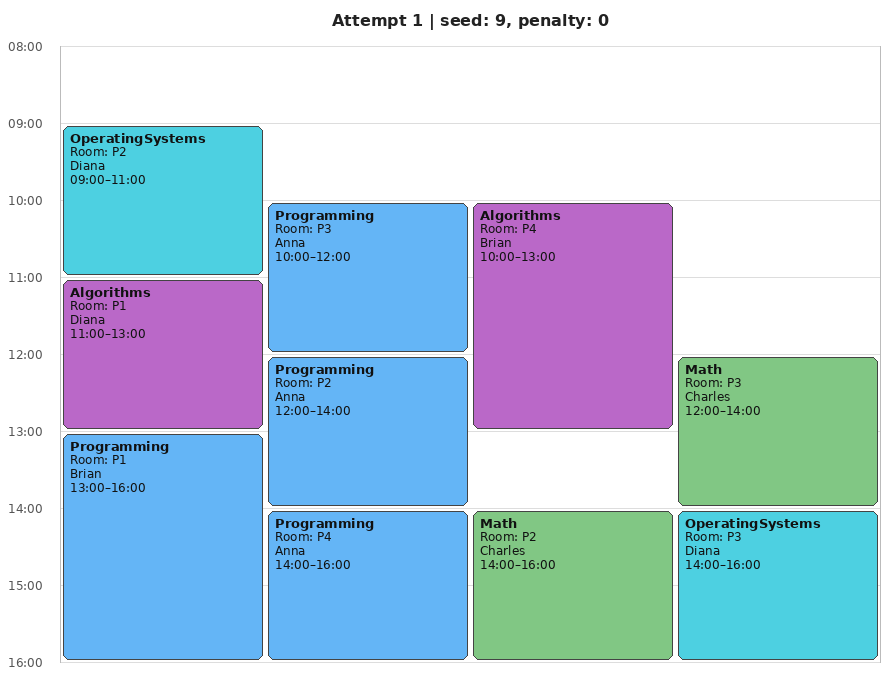

In [6]:
attempts = []
for attempt in range(1, 11):
  seed = 8 + attempt
  ga = pygad.GA(
    num_generations=500,
    num_parents_mating=20,
    sol_per_pop=100,
    num_genes=3 * N,
    gene_type=int,
    gene_space=gene_space,
    fitness_func=fitness_func,
    parent_selection_type="tournament",
    K_tournament=4,
    keep_elitism=5,
    mutation_type="random",
    crossover_type="single_point",
    mutation_num_genes=3,
    stop_criteria=["reach_1.0"],
    random_seed=seed,
  )
  ga.run()
  solution, fit, _ = ga.best_solution()
  attempts.append((attempt, seed, solution.copy()))
  print(f"attempt {attempt}| seed: {seed}, generations: {ga.generations_completed}, penalty: {penalty(solution)}")
  if penalty(solution) == 0:
    break

for i in range(0, len(attempts), 3):
  show_attempts(attempts[i:i + 3])

## Task 2

### Algorithm for initial population generation
```
1. generate a random schedule
2. visit lectures from longest to shortest, with random order for ties
3. sample six placements and keep the best one, including the current placement
```

The idea is to improve the random schedules before running the GA. Longer
lectures are considered first because they have fewer possible start times.

### Custom crossover function

Each lecture is defined by three parameters, so the child inherits the whole
lecture block from one parent.

### Custom mutation function

Choose a conflicting lecture and test changes to its room, teacher or start
time. Keep the best improvement. With a small probability, try a random
change instead. If there are no conflicts, only the random move is used.

### Comparison

Use the same GA settings and seeds to compare the starting population and
the operators. Record the best fitness from generation 0, the time to a
valid schedule (including initialization), and the time spent in each step.

In [7]:
import time

Baseline | Seed: 9 | Valid: not found | Total: 462.8 ms
Improved initialization | Seed: 9 | Valid: not found | Total: 552.4 ms
Custom operators | Seed: 9 | Valid: 95.3 ms | Total: 95.5 ms
Both | Seed: 9 | Valid: 84.2 ms | Total: 84.8 ms
Baseline | Seed: 53 | Valid: not found | Total: 444.2 ms
Improved initialization | Seed: 53 | Valid: not found | Total: 491.6 ms
Custom operators | Seed: 53 | Valid: 42.0 ms | Total: 42.9 ms
Both | Seed: 53 | Valid: 112.6 ms | Total: 112.8 ms
Baseline | Seed: 81 | Valid: not found | Total: 438.8 ms
Improved initialization | Seed: 81 | Valid: 405.0 ms | Total: 405.8 ms
Custom operators | Seed: 81 | Valid: not found | Total: 1438.3 ms
Both | Seed: 81 | Valid: 107.9 ms | Total: 108.6 ms


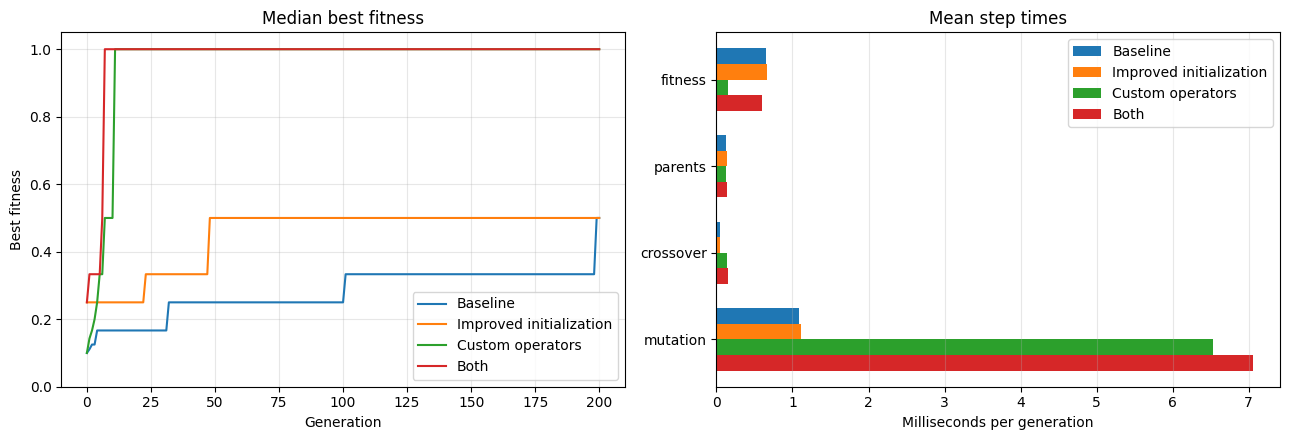

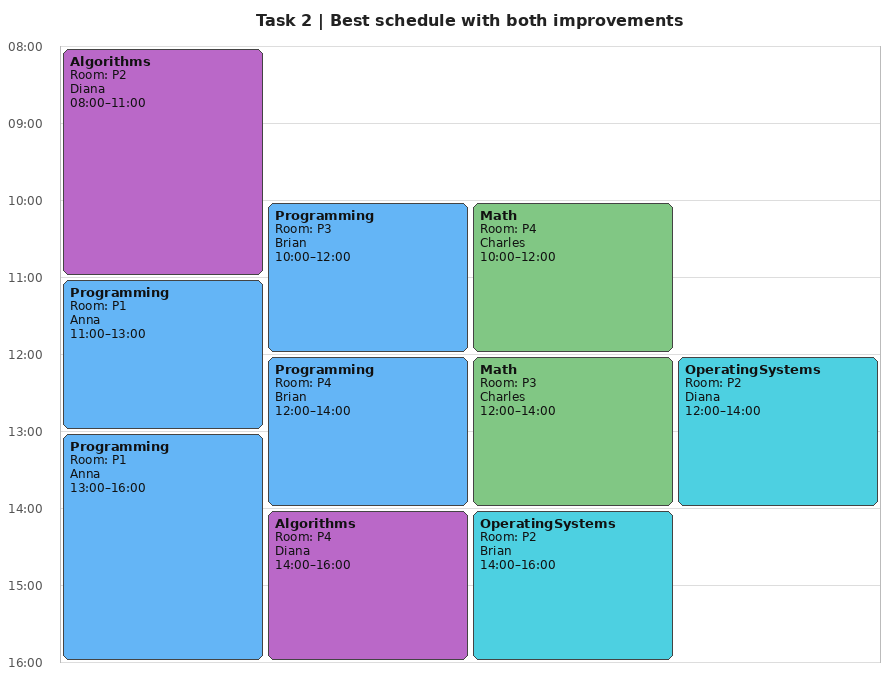

In [8]:
def generate_initial_population(pop_size, seed):
  rng = random.Random(seed)
  pop = np.zeros((pop_size, 3 * N), dtype=int)

  for i in range(pop_size):
    order = list(range(N))
    rng.shuffle(order)
    order.sort(key=lambda k: lec_dur[k], reverse=True)

    sol = np.array([rng.choice(gene_space[g]) for g in range(3 * N)])
    for k in order:
      best_pen = penalty(sol)
      best_choice = sol[3 * k : 3 * k + 3].copy()
      # Sample up to 6 random (room, teacher, start) placements per lecture
      for _ in range(6):
        r = rng.choice(gene_space[3 * k])
        t = rng.choice(gene_space[3 * k + 1])
        s = rng.choice(gene_space[3 * k + 2])
        sol[3 * k : 3 * k + 3] = [r, t, s]
        p = penalty(sol)
        if p < best_pen:
          best_pen, best_choice = p, (r, t, s)
      sol[3 * k : 3 * k + 3] = best_choice
    pop[i] = sol

  return pop


# ---------- 2. Custom Crossover & Mutation ----------
def block_crossover(parents, offspring_size, ga_instance):
  """Swaps complete [room, teacher, start] class blocks between parents."""
  offspring = np.empty(offspring_size, dtype=int)
  for i in range(offspring_size[0]):
    p1 = parents[i % len(parents)].reshape(N, 3)
    p2 = parents[(i + 1) % len(parents)].reshape(N, 3)
    mask = ga_instance.numpy_random_generator.rand(N, 1) < 0.5
    offspring[i] = np.where(mask, p1, p2).flatten()
  return offspring


def targeted_mutation(offspring, ga_instance):
  """Try one repair or one random change per offspring."""
  rng = ga_instance.numpy_random_generator

  for sol in offspring:
    invalid = invalid_lectures(sol)
    if rng.random() < 0.10:
      g = rng.randint(3 * N)
      alternatives = [val for val in gene_space[g] if val != sol[g]]
      if alternatives:
        sol[g] = rng.choice(alternatives)
    elif invalid.size:
      k = int(rng.choice(invalid))
      best_pen = penalty(sol)
      best_idx, best_value = 3 * k, sol[3 * k]
      for g in range(3 * k, 3 * k + 3):
        original = sol[g]
        for val in gene_space[g]:
          if val != original:
            sol[g] = val
            p = penalty(sol)
            if p < best_pen:
              best_pen, best_idx, best_value = p, g, val
        sol[g] = original
      sol[best_idx] = best_value

  return offspring


class Profiler:
  def __init__(self):
    self.times = {k: [] for k in ["fitness", "parents", "crossover", "mutation"]}
    self.fitness = []
    self.fitness_ms = 0.0
    self.valid_ms = None

  def score(self, ga, solution, solution_idx):
    start = time.perf_counter()
    value = fitness_func(ga, solution, solution_idx)
    self.fitness_ms += (time.perf_counter() - start) * 1000
    if value == 1.0 and self.valid_ms is None:
      self.valid_ms = (time.perf_counter() - self.start) * 1000
    return value

  def on_fitness(self, ga, values):
    if not self.fitness:
      self.fitness.append(float(np.max(values)))
      self.fitness_ms = 0.0  # generation 0 is included in total time
    self.t = time.perf_counter()

  def on_parents(self, ga, parents):
    self.record_step("parents")

  def on_crossover(self, ga, offspring):
    self.record_step("crossover")

  def on_mutation(self, ga, offspring):
    self.record_step("mutation")

  def record_step(self, step):
    now = time.perf_counter()
    self.times[step].append((now - self.t) * 1000)
    self.t = now

  def on_generation(self, ga):
    self.times["fitness"].append(self.fitness_ms)
    self.fitness_ms = 0.0
    self.fitness.append(float(np.max(ga.last_generation_fitness)))


configurations = {
  "Baseline": (False, False),
  "Improved initialization": (True, False),
  "Custom operators": (False, True),
  "Both": (True, True),
}
seeds = [9, 53, 81]
results = {name: [] for name in configurations}
best_task2 = None
best_task2_penalty = float("inf")
step_names = ["fitness", "parents", "crossover", "mutation"]

for seed in seeds:
  for name, (use_init, use_custom) in configurations.items():
    profile = Profiler()
    profile.start = time.perf_counter()
    initial_pop = generate_initial_population(40, seed) if use_init else None
    ga = pygad.GA(
      num_generations=200, sol_per_pop=40, num_parents_mating=20,
      num_genes=3 * N, gene_space=gene_space, gene_type=int,
      keep_elitism=2, random_seed=seed, initial_population=initial_pop,
      crossover_type=block_crossover if use_custom else "single_point",
      mutation_type=targeted_mutation if use_custom else "random",
      **({} if use_custom else {"mutation_percent_genes": 10}),
      fitness_func=profile.score, stop_criteria=["reach_1.0"],
      on_fitness=profile.on_fitness, on_parents=profile.on_parents,
      on_crossover=profile.on_crossover, on_mutation=profile.on_mutation,
      on_generation=profile.on_generation,
    )
    ga.run()
    total_ms = (time.perf_counter() - profile.start) * 1000
    results[name].append(profile)
    if use_init and use_custom:
      solution = ga.population[np.argmax(ga.last_generation_fitness)]
      if penalty(solution) < best_task2_penalty:
        best_task2 = solution.copy()
        best_task2_penalty = penalty(solution)
    valid_time = f"{profile.valid_ms:.1f} ms" if profile.valid_ms is not None else "not found"
    print(f"{name} | Seed: {seed} | Valid: {valid_time} | Total: {total_ms:.1f} ms")


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
y = np.arange(len(step_names))
for i, (name, runs) in enumerate(results.items()):
  # Extend stopped runs with their final fitness to compare at each generation.
  curves = [np.pad(run.fitness, (0, 201 - len(run.fitness)), mode="edge") for run in runs]
  ax1.plot(np.median(curves, axis=0), label=name)
  times = [np.mean([ms for run in runs for ms in run.times[step]]) for step in step_names]
  ax2.barh(y + 0.18 * (i - 1.5), times, height=0.18, label=name)

ax1.set(title="Median best fitness", xlabel="Generation", ylabel="Best fitness", ylim=(0, 1.05))
ax1.grid(alpha=0.3)
ax1.legend()
ax2.set(title="Mean step times", xlabel="Milliseconds per generation",
        yticks=y, yticklabels=step_names)
ax2.invert_yaxis()
ax2.grid(axis="x", alpha=0.3)
ax2.legend()
plt.tight_layout()
plt.show()

show_schedule(best_task2, "Task 2 | Best schedule with both improvements")

## Task 3

### Preferences

Add a penalty for hours outside the teacher's liked window and for hours
inside the disliked window. An hour can contribute to both penalties.
Teachers without a preference have no preference penalty for that window.

### Balance

Compare each teacher's assigned hours with the ideal equal share of total
lecture hours. Add the absolute deviations, including teachers assigned zero
hours.

### Single and multi-objective fitness

The single-objective GA adds both soft penalties. Its hard penalty weight is
greater than the largest possible total soft penalty. The multi-objective GA
keeps the two soft scores separate and gives every valid schedule better
scores on both objectives than any invalid schedule.

Both runs start from the same population for each seed. To compare the
results, choose the valid schedule with the lowest sum of soft penalties
from the final population of each run. If none is valid, report the lowest
hard penalty found in that population.

In [9]:
import json
from pathlib import Path
def read_preferences(path):
  dc = {}
  with open(path, "r", encoding="utf-8") as f:
    for line in f:
      line = line.strip()
      if not line:
        continue

      # Split at the first '{' to separate the teacher's name from the JSON-like dictionary
      key, raw_data = line.split("{", 1)

      # Re-attach '{' and replace curly/smart quotes with standard double quotes for valid JSON
      clean_json = ("{" + raw_data).replace("“", '"').replace("”", '"')

      dc[key.strip()] = json.loads(clean_json)
  return dc

pref_path = input_dir / "preferences.txt"
if not pref_path.exists():
  pref_path = input_dir / "Preferences.txt"
prefs = read_preferences(pref_path)

In [10]:
# ---------- Task 3 preprocessing ----------
def prepare_preferences(preferences):
  global num_teachers, like_start, like_end, dislike_start, dislike_end, IDEAL_HOURS, W_HARD
  num_teachers = len(teacher_names)
  like_start = np.zeros(num_teachers, dtype=int)
  like_end = np.zeros(num_teachers, dtype=int)
  dislike_start = np.zeros(num_teachers, dtype=int)
  dislike_end = np.zeros(num_teachers, dtype=int)

  for t, tname in enumerate(teacher_names):
    t_pref = preferences.get(tname, {})
    if "likes" in t_pref and t_pref["likes"]:
      like_start[t], like_end[t] = t_pref["likes"]
    if "dislikes" in t_pref and t_pref["dislikes"]:
      dislike_start[t], dislike_end[t] = t_pref["dislikes"]

  IDEAL_HOURS = lec_dur.sum() / num_teachers
  # Preferences and balance each contribute at most twice the lecture hours.
  W_HARD = 4 * int(lec_dur.sum()) + 1

prepare_preferences(prefs)


def interval_overlap(s1, e1, s2, e2):
  """Vectorized overlap in hours between two sets of intervals."""
  return np.maximum(0, np.minimum(e1, e2) - np.maximum(s1, s2))


def soft_penalty_terms(gene):
  _, teacher, start, end = decode(gene)

  # 1. Preferences penalty
  # Hours overlapping disliked window
  bad_dislike = interval_overlap(
      start, end, dislike_start[teacher], dislike_end[teacher]
  )

  # Hours outside liked window (only for teachers who specified a 'likes' window)
  has_likes = like_end[teacher] > like_start[teacher]
  good_like = interval_overlap(start, end, like_start[teacher], like_end[teacher])
  bad_like = np.where(has_likes, lec_dur - good_like, 0)

  p_pref = float((bad_dislike + bad_like).sum())

  # 2. Teacher balance penalty (total deviation from ideal equal hours)
  teacher_hours = np.bincount(teacher, weights=lec_dur, minlength=num_teachers)
  p_balance = float(np.abs(teacher_hours - IDEAL_HOURS).sum())

  return p_pref, p_balance

def single_fitness_func(ga_instance, solution, solution_idx):
  hard = penalty(solution)
  p_pref, p_balance = soft_penalty_terms(solution)
  return 1.0 / (1.0 + W_HARD * hard + p_pref + p_balance)


def multi_fitness_func(ga_instance, solution, solution_idx):
  hard = penalty(solution)
  if hard:
    return [-float(hard), -float(hard)]
  p_pref, p_balance = soft_penalty_terms(solution)
  return [1.0 / (1.0 + p_pref), 1.0 / (1.0 + p_balance)]


def schedule_rank(solution):
  return penalty(solution), sum(soft_penalty_terms(solution))


def evaluate_schedule(gene, label):
  p_room, p_teacher, p_window, p_eligible = penalty_terms(gene)
  p_pref, p_balance = soft_penalty_terms(gene)
  print(f"{label} | Valid: {penalty(gene) == 0} | "
        f"Hard (room, teacher, window, eligibility): "
        f"{p_room}, {p_teacher}, {p_window}, {p_eligible} | "
        f"Preferences: {p_pref:.1f}h | Balance: {p_balance:.1f}h")

Single objective | Seed: 9 | GA time: 383.3 ms | Valid: True | Hard (room, teacher, window, eligibility): 0, 0, 0, 0 | Preferences: 16.0h | Balance: 4.0h
Multi-objective | Seed: 9 | GA time: 4230.7 ms | Valid: True | Hard (room, teacher, window, eligibility): 0, 0, 0, 0 | Preferences: 17.0h | Balance: 4.0h
Single objective | Seed: 53 | GA time: 1816.8 ms | Valid: False | Hard (room, teacher, window, eligibility): 0, 0, 1, 0 | Preferences: 17.0h | Balance: 4.0h
Multi-objective | Seed: 53 | GA time: 4753.2 ms | Valid: True | Hard (room, teacher, window, eligibility): 0, 0, 0, 0 | Preferences: 16.0h | Balance: 4.0h
Single objective | Seed: 81 | GA time: 1845.1 ms | Valid: False | Hard (room, teacher, window, eligibility): 0, 0, 1, 0 | Preferences: 16.0h | Balance: 7.0h
Multi-objective | Seed: 81 | GA time: 4150.6 ms | Valid: True | Hard (room, teacher, window, eligibility): 0, 0, 0, 0 | Preferences: 16.0h | Balance: 4.0h

Single objective | Best schedule across seeds | Valid: True


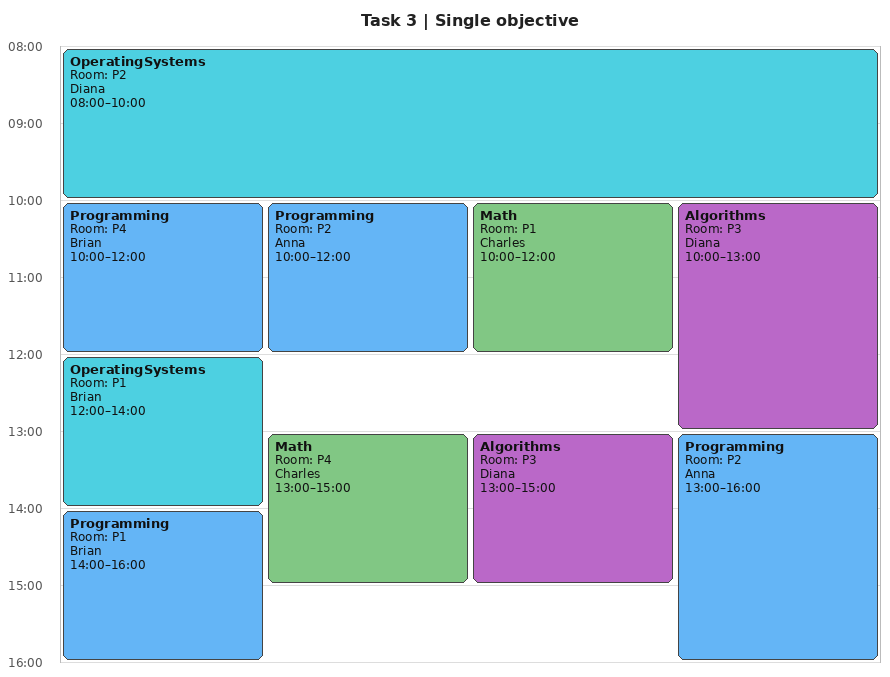


Multi-objective | Best schedule across seeds | Valid: True


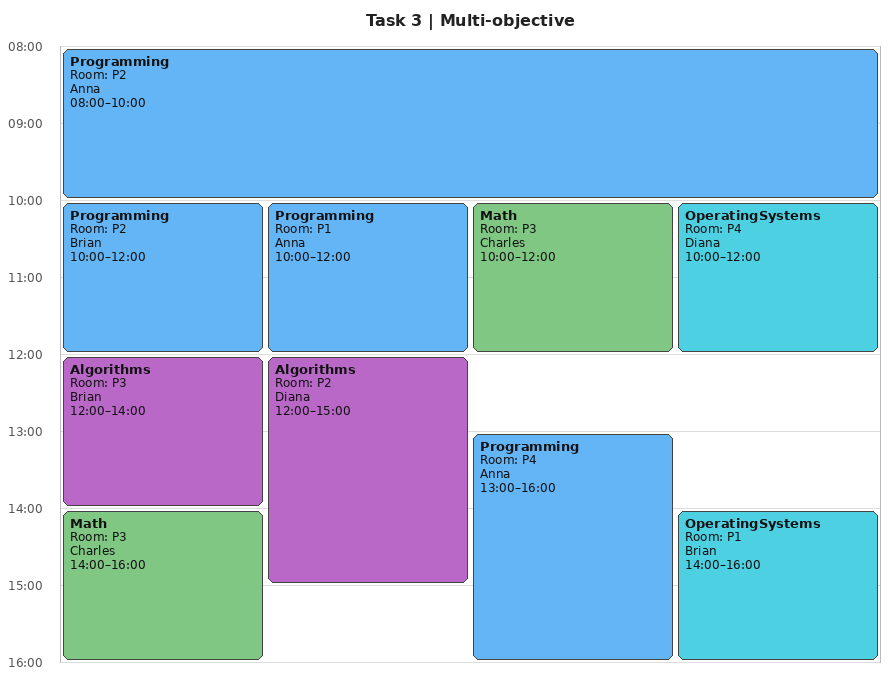

In [11]:
# Compare the same initial population and search budget for each seed.
task3_results = []
for seed in seeds:
  initial_pop = generate_initial_population(40, seed)
  for label, score, selection in [
    ("Single objective", single_fitness_func, "tournament"),
    ("Multi-objective", multi_fitness_func, "nsga2"),
  ]:
    ga = pygad.GA(
      num_generations=200, sol_per_pop=40, num_parents_mating=20,
      num_genes=3 * N, gene_space=gene_space, gene_type=int,
      initial_population=initial_pop.copy(), fitness_func=score,
      parent_selection_type=selection, keep_elitism=2, random_seed=seed,
      crossover_type=block_crossover, mutation_type=targeted_mutation,
    )
    start = time.perf_counter()
    ga.run()
    elapsed_ms = (time.perf_counter() - start) * 1000
    best_sol = min(ga.population, key=schedule_rank).copy()
    task3_results.append((label, seed, best_sol))
    evaluate_schedule(best_sol, f"{label} | Seed: {seed} | GA time: {elapsed_ms:.1f} ms")

for label in ("Single objective", "Multi-objective"):
  best_sol = min((sol for name, _, sol in task3_results if name == label), key=schedule_rank)
  print(f"\n{label} | Best schedule across seeds | Valid: {penalty(best_sol) == 0}")
  show_schedule(best_sol, f"Task 3 | {label}")

## Task 4

Use generated small and large inputs with two difficulty levels. Easy inputs
have room and teacher slack. Difficult inputs have staggered room windows,
restricted eligibility and little spare room time. The generator records a
known valid chromosome for each of these four cases. The overload case
requires more room hours than are available, so it is impossible.

The experiment cells compare input datasets, GA settings, Task 2 operators,
and Task 3 objectives. Each uses the same three seeds. The tables summarize
all seeds. Side-by-side timetables use the first seed so the examples are
comparable. Timing includes population initialization and excludes plotting.

In [12]:
# ---------- generate Task 4 inputs ----------
def generate_case(folder, room_count, blocks, difficult, seed, overload=False):
  rng = random.Random(seed)
  rooms, courses, qualifications, preferences, witness = {}, {}, {}, {}, []
  teacher_count = room_count if difficult else room_count + 2
  teacher_names = [f"T{i + 1:02d}" for i in range(teacher_count)]
  qualifications = {name: [] for name in teacher_names}
  preferences = {name: {"likes": [9, 13], "dislikes": [15, 18]} for name in teacher_names}
  for r in range(room_count):
    opening = 8 + (r % 2 if difficult else 0)
    room = f"R{r + 1:02d}"
    rooms[room] = [opening, opening + (2 * blocks if difficult else 12)]
    for block in range(blocks):
      name = f"Course {r * blocks + block + 1:02d}"
      duration = 2 if difficult else rng.choice([1, 2])
      courses[name] = [duration]
      teacher = r
      alternatives = [t for t in range(teacher_count) if t != teacher]
      extra = rng.sample(alternatives, 1) if difficult and block % 3 == 0 else []
      if not difficult:
        extra = rng.sample(alternatives, min(3, len(alternatives)))
      for t in [teacher] + extra:
        qualifications[teacher_names[t]].append(name)
      witness.extend([r, teacher, opening + 2 * block])

  if overload:
    courses["Extra course"] = [2]
    qualifications[teacher_names[0]].append("Extra course")

  folder.mkdir(parents=True, exist_ok=True)
  for filename, rows in [("Classes.txt", courses), ("Classrooms.txt", rooms),
                         ("Teachers.txt", qualifications)]:
    content = "\n".join(f"{name} [{', '.join(map(str, values))}]" for name, values in rows.items())
    (folder / filename).write_text(content + "\n", encoding="utf-8")
  lines = [f"{name} {json.dumps(pref)}" for name, pref in preferences.items()]
  (folder / "preferences.txt").write_text("\n".join(lines) + "\n", encoding="utf-8")
  return None if overload else np.asarray(witness, dtype=int)


case_specs = {
  "small_easy": (3, 3, False),
  "small_difficult": (3, 3, True),
  "large_easy": (7, 5, False),
  "large_difficult": (7, 5, True),
  "room_overload": (3, 3, True),
}
task4_dir = Path("task4_inputs")
witnesses = {
  name: generate_case(task4_dir / name, *spec, seed=42, overload=name == "room_overload")
  for name, spec in case_specs.items()
}

In [13]:
# ---------- run and compare ----------
from contextlib import contextmanager

@contextmanager
def use_case(name):
  original = classes, crooms, teachers
  folder = task4_dir / name
  try:
    prepare_schedule(*(read_file(folder / filename) for filename in required_files))
    prepare_preferences(read_preferences(folder / "preferences.txt"))
    yield
  finally:
    prepare_schedule(*original)
    prepare_preferences(prefs)


def run_case(seed, use_init=False, use_custom=False, generations=80, pop_size=24,
             mutation_percent=10, objective="hard"):
  profile = Profiler()
  profile.start = time.perf_counter()
  initial = generate_initial_population(pop_size, seed) if use_init else None
  soft = objective != "hard"
  best = None
  history, balance_path = [], []

  def record(ga, values):
    nonlocal best
    if soft:
      candidate = min(ga.population, key=schedule_rank)
      if best is None or schedule_rank(candidate) < schedule_rank(best):
        best = candidate.copy()
      pref, balance = soft_penalty_terms(best)
      history.append(pref if penalty(best) == 0 else np.nan)
      balance_path.append(balance if penalty(best) == 0 else np.nan)

  def on_fitness(ga, values):
    profile.on_fitness(ga, values)
    if not history:
      record(ga, values)

  def on_generation(ga):
    profile.on_generation(ga)
    record(ga, ga.last_generation_fitness)

  scores = {"hard": profile.score, "single": single_fitness_func, "multi": multi_fitness_func}
  ga = pygad.GA(
    num_generations=generations, sol_per_pop=pop_size, num_parents_mating=pop_size // 2,
    num_genes=3 * N, gene_space=gene_space, gene_type=int, keep_elitism=2,
    random_seed=seed, initial_population=initial, fitness_func=scores[objective],
    parent_selection_type="nsga2" if objective == "multi" else "tournament",
    crossover_type=block_crossover if use_custom else "single_point",
    mutation_type=targeted_mutation if use_custom else "random",
    **({} if use_custom else {"mutation_percent_genes": mutation_percent}),
    stop_criteria=None if soft else ["reach_1.0"],
    on_fitness=on_fitness, on_generation=on_generation,
  )
  ga.run()
  total_ms = (time.perf_counter() - profile.start) * 1000
  if not soft:
    best = ga.population[np.argmax(ga.last_generation_fitness)].copy()
  return dict(gene=best, hard=penalty(best), pref=soft_penalty_terms(best)[0],
              balance=soft_penalty_terms(best)[1], total_ms=total_ms,
              valid_ms=profile.valid_ms, fitness=profile.fitness,
              preference_history=history, balance_history=balance_path)


def plot_comparison(results, soft=False):
  """Plot median curves and runtime. Soft curves use valid schedules only."""
  fig, axes = plt.subplots(1, 3 if soft else 2, figsize=(14 if soft else 11, 4))
  metrics = [("preference_history", "Preference penalty (h)"),
             ("balance_history", "Balance penalty (h)")] if soft else [("fitness", "Best fitness")]
  for ax, (metric, title) in zip(axes, metrics):
    for label, runs in results.items():
      length = max(len(run[metric]) for run in runs)
      curves = np.array([np.pad(run[metric], (0, length - len(run[metric])), mode="edge") for run in runs])
      # If a seed has no valid schedule yet, leave it out of the soft median.
      curve = [np.median(col[np.isfinite(col)]) if np.isfinite(col).any() else np.nan for col in curves.T]
      ax.plot(curve, label=label)
    ax.set(xlabel="Generation", ylabel=title)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
  runtime = [np.median([run["total_ms"] for run in runs]) for runs in results.values()]
  axes[-1].barh(list(results), runtime)
  axes[-1].set(xlabel="Median total time (ms)")
  fig.tight_layout()
  plt.show()


def show_comparison(results, soft=False):
  """Summarize all seeds and show first-seed schedule images side by side."""
  header = "| Variant | Valid runs | Median hard penalty | Median total ms |"
  if soft:
    header += " Median preference h | Median balance h |"
  else:
    header += " Median ms to valid (successful runs) |"
  from IPython.display import Markdown
  rows = [header, "|" + " --- |" * 5 + (" --- |" if soft else "")]
  figures = []
  for label, runs in results.items():
    valid = [run for run in runs if run["hard"] == 0]
    row = f"| {label} | {len(valid)}/{len(runs)} | {np.median([r['hard'] for r in runs]):g} | {np.median([r['total_ms'] for r in runs]):.1f} |"
    if soft:
      row += " ".join(f"{np.median([r[k] for r in valid]):.1f} |" if valid else "— |" for k in ("pref", "balance"))
    else:
      row += f" {np.median([r['valid_ms'] for r in valid]):.1f} |" if valid else " — |"
    rows.append(row)
    figures.append(runs[0]["image"])
  display(Markdown("\n".join(rows)))
  for start in range(0, len(figures), 2):
    pair = figures[start:start + 2]
    fig, axes = plt.subplots(1, len(pair), figsize=(7 * len(pair), 8), squeeze=False)
    for ax, image in zip(axes[0], pair):
      ax.imshow(image, interpolation="none")
      ax.axis("off")
    fig.tight_layout()
    plt.show()


def compare_runs(case, variants):
  with use_case(case):
    results = {}
    for label, options in variants.items():
      runs = [run_case(seed, **options) for seed in seeds]
      runs[0]["image"] = render_image(runs[0]["gene"], f"{label} | seed {seeds[0]} | hard {runs[0]['hard']}")
      results[label] = runs
    return results

### Small, large, easy and difficult inputs

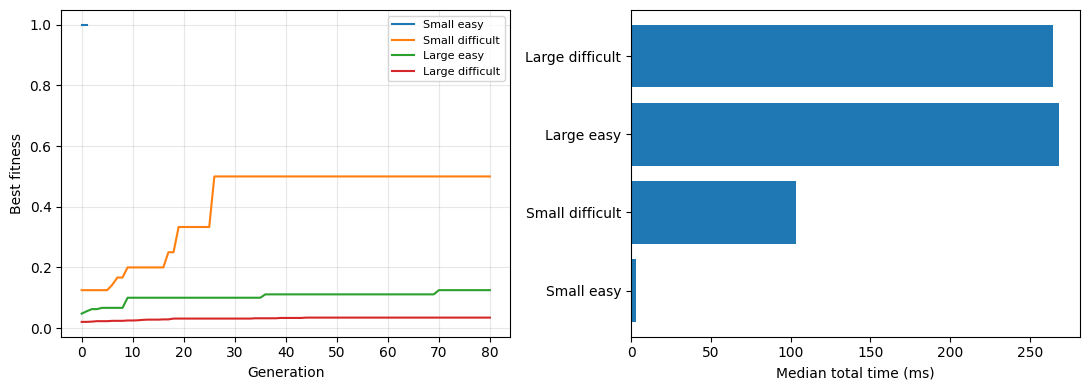

| Variant | Valid runs | Median hard penalty | Median total ms | Median ms to valid (successful runs) |
| --- | --- | --- | --- | --- |
| Small easy | 3/3 | 0 | 3.3 | 1.4 |
| Small difficult | 0/3 | 1 | 103.5 | — |
| Large easy | 0/3 | 7 | 267.8 | — |
| Large difficult | 0/3 | 28 | 264.5 | — |

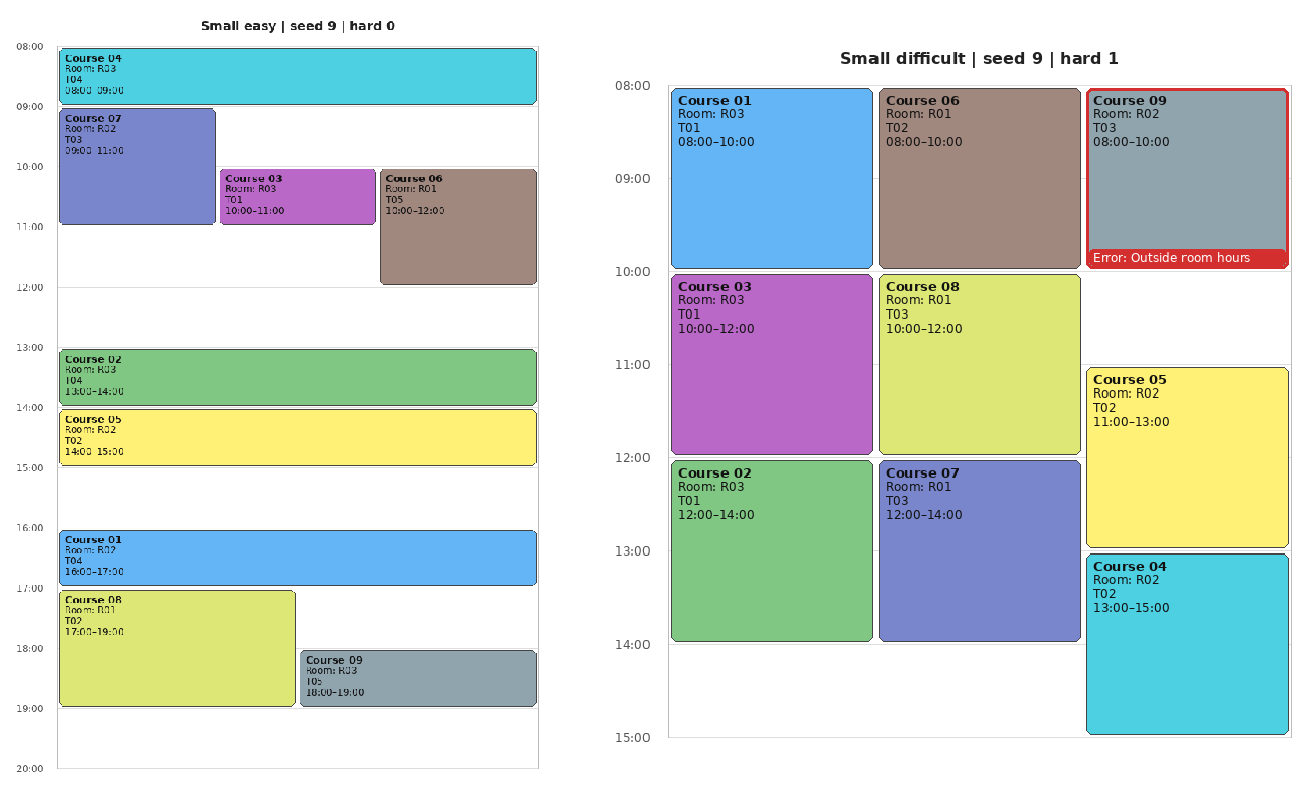

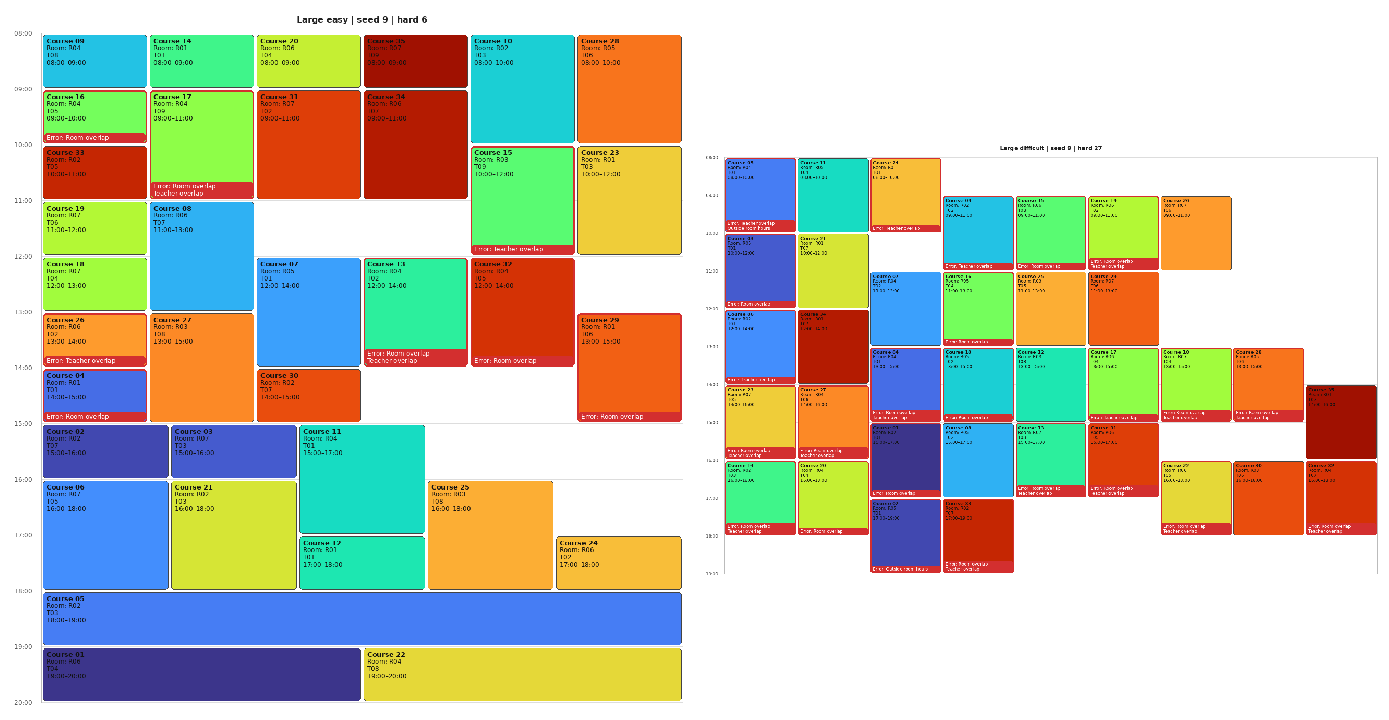

In [14]:
size_results = {}
for case in ("small_easy", "small_difficult", "large_easy", "large_difficult"):
  with use_case(case):
    assert penalty(witnesses[case]) == 0
  label = case.replace("_", " ").capitalize()
  size_results.update(compare_runs(case, {label: {}}))

plot_comparison(size_results)
show_comparison(size_results)

### GA parameter comparison

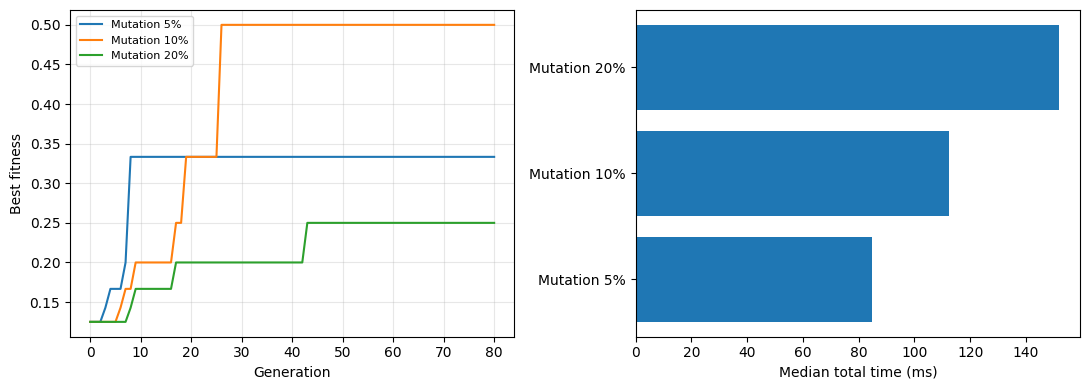

| Variant | Valid runs | Median hard penalty | Median total ms | Median ms to valid (successful runs) |
| --- | --- | --- | --- | --- |
| Mutation 5% | 0/3 | 2 | 84.9 | — |
| Mutation 10% | 0/3 | 1 | 112.3 | — |
| Mutation 20% | 0/3 | 3 | 151.8 | — |

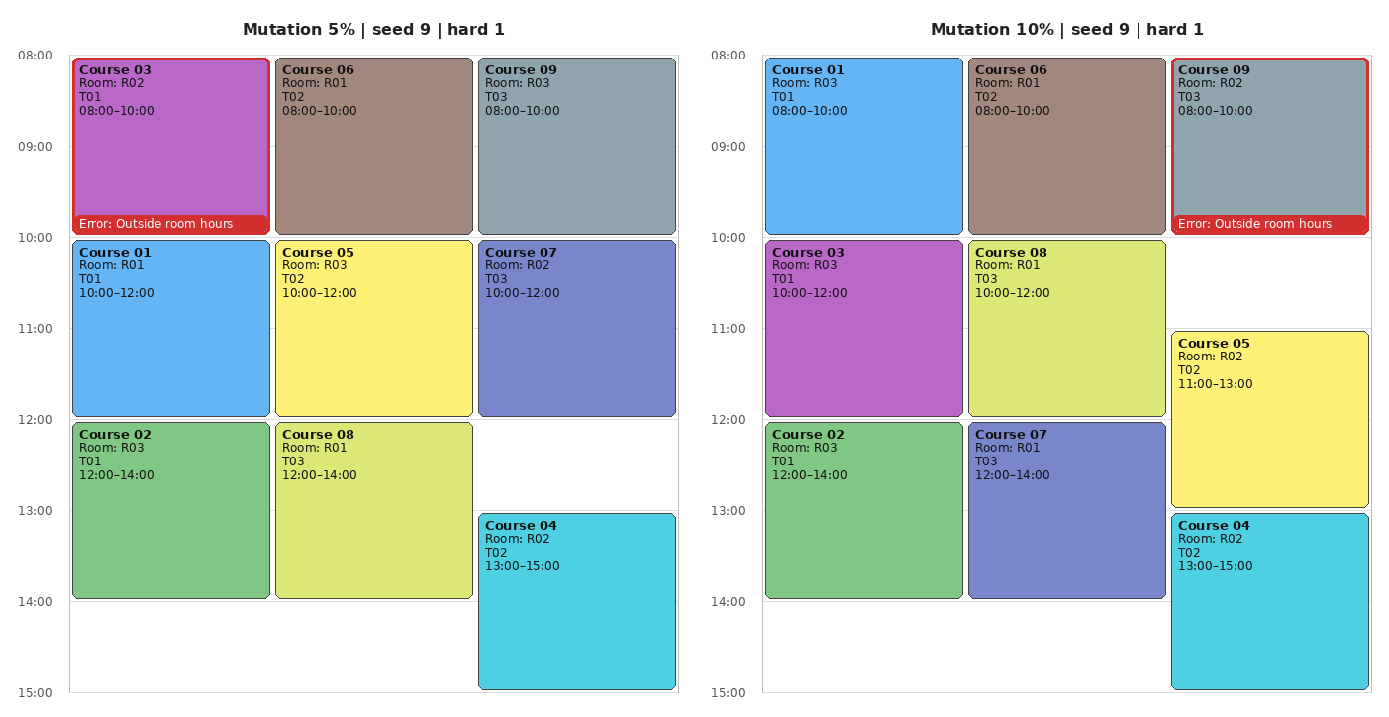

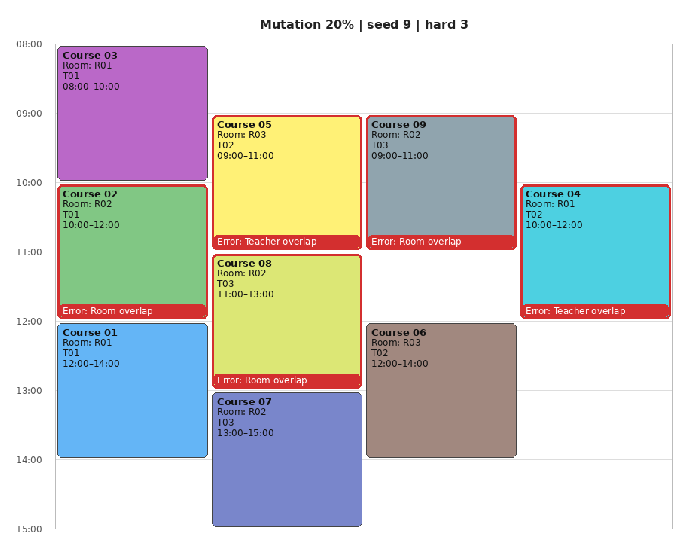

In [15]:
# Change only mutation intensity. Population and generation budget are fixed.
parameter_results = compare_runs("small_difficult", {
  "Mutation 5%": {"mutation_percent": 5},
  "Mutation 10%": {"mutation_percent": 10},
  "Mutation 20%": {"mutation_percent": 20},
})
plot_comparison(parameter_results)
show_comparison(parameter_results)

### Improved initialization and custom operators

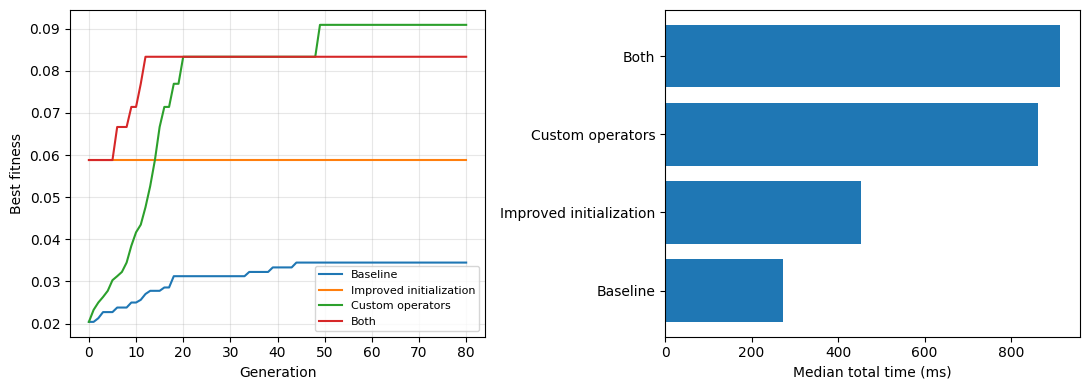

| Variant | Valid runs | Median hard penalty | Median total ms | Median ms to valid (successful runs) |
| --- | --- | --- | --- | --- |
| Baseline | 0/3 | 28 | 271.9 | — |
| Improved initialization | 0/3 | 16 | 454.1 | — |
| Custom operators | 0/3 | 10 | 862.7 | — |
| Both | 0/3 | 11 | 913.6 | — |

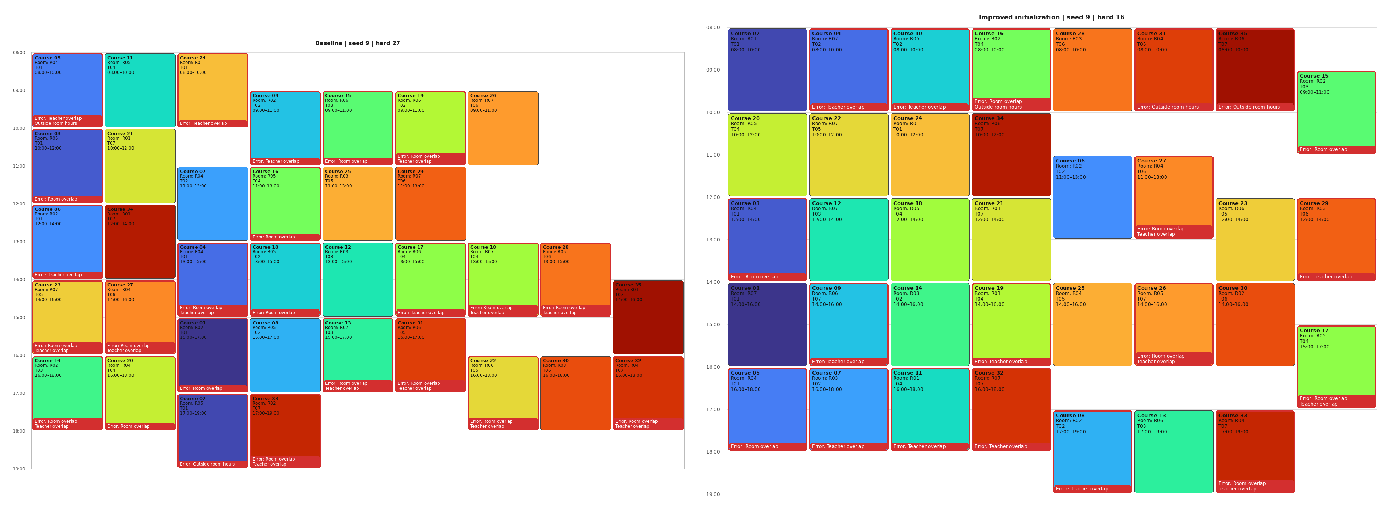

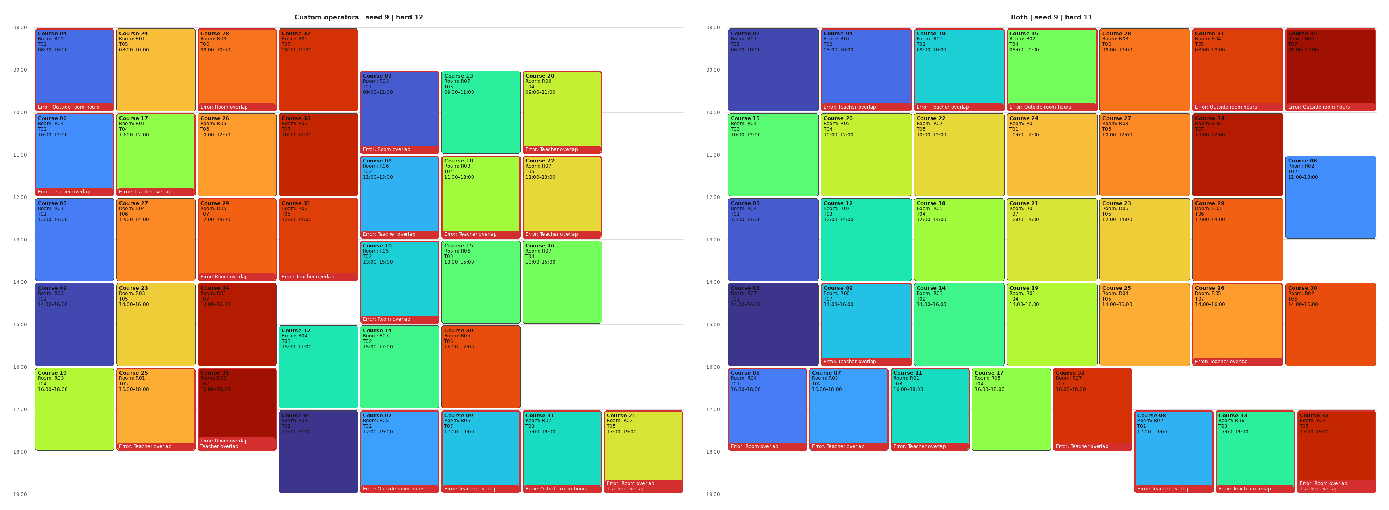

In [16]:
operator_results = compare_runs("large_difficult", {
  label: {"use_init": use_init, "use_custom": use_custom}
  for label, (use_init, use_custom) in configurations.items()
})
plot_comparison(operator_results)
show_comparison(operator_results)

### Single objective and multi-objective

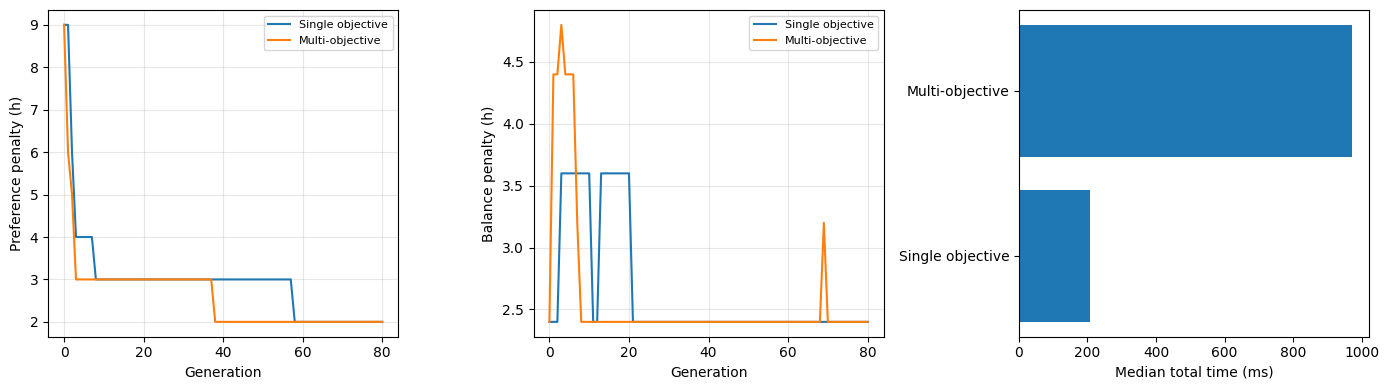

| Variant | Valid runs | Median hard penalty | Median total ms | Median preference h | Median balance h |
| --- | --- | --- | --- | --- | --- |
| Single objective | 3/3 | 0 | 206.3 |2.0 | 2.4 |
| Multi-objective | 3/3 | 0 | 972.0 |2.0 | 2.4 |

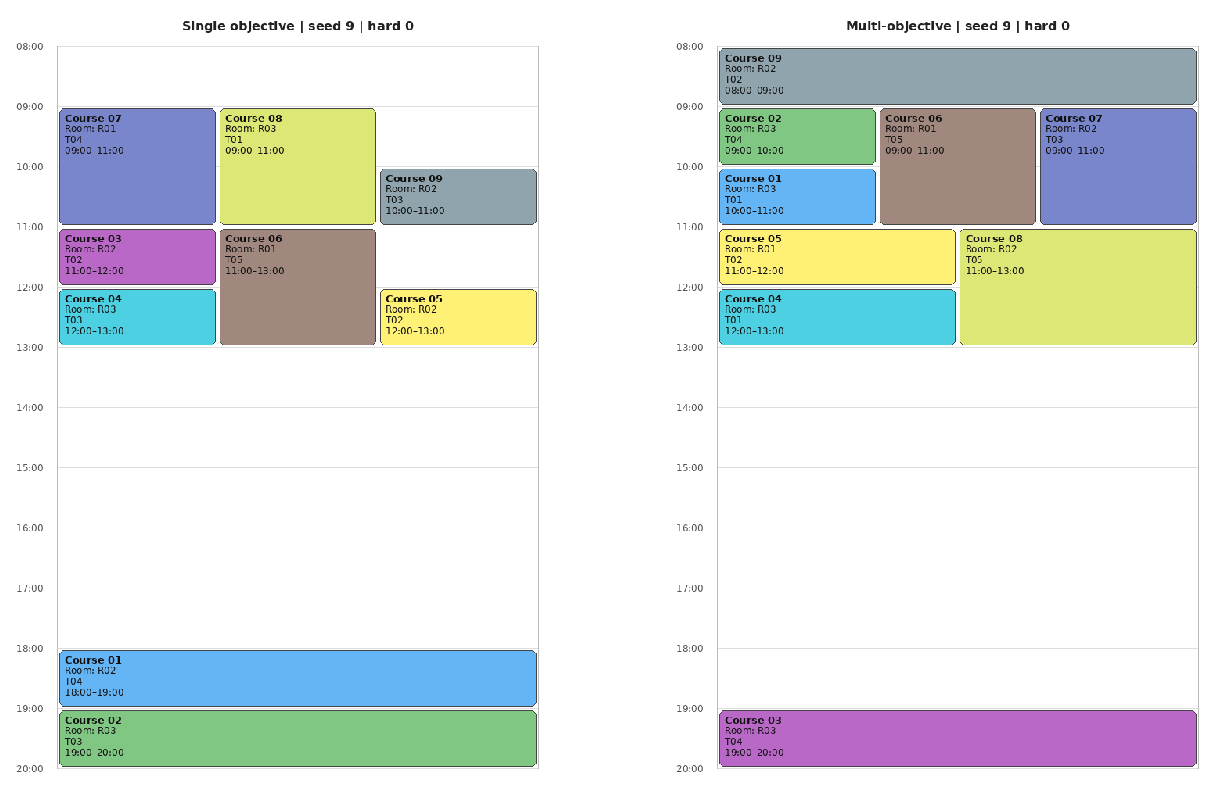

In [17]:
objective_results = compare_runs("small_easy", {
  "Single objective": {"use_init": True, "use_custom": True, "objective": "single"},
  "Multi-objective": {"use_init": True, "use_custom": True, "objective": "multi"},
})
plot_comparison(objective_results, soft=True)
show_comparison(objective_results, soft=True)

### Failure cases

Room overload | Demand: 20h | Capacity: 18h
Large difficult has a known valid timetable. This run has a deliberately short budget.


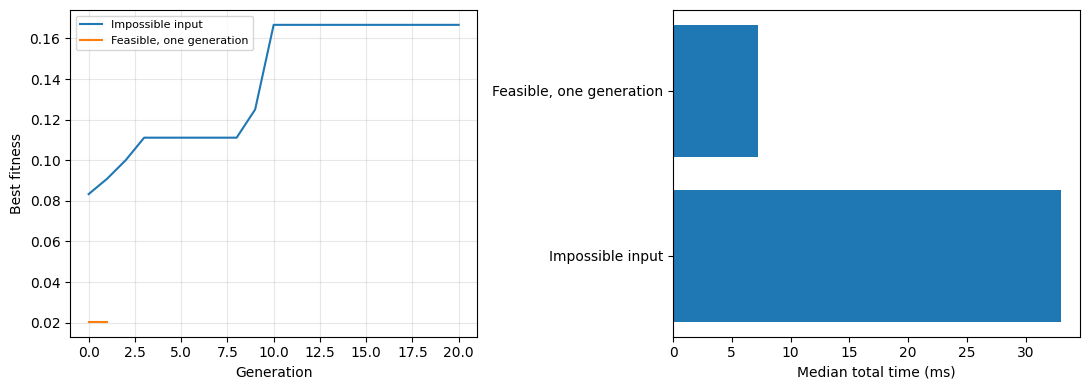

| Variant | Valid runs | Median hard penalty | Median total ms | Median ms to valid (successful runs) |
| --- | --- | --- | --- | --- |
| Impossible input | 0/3 | 5 | 33.0 | — |
| Feasible, one generation | 0/3 | 48 | 7.2 | — |

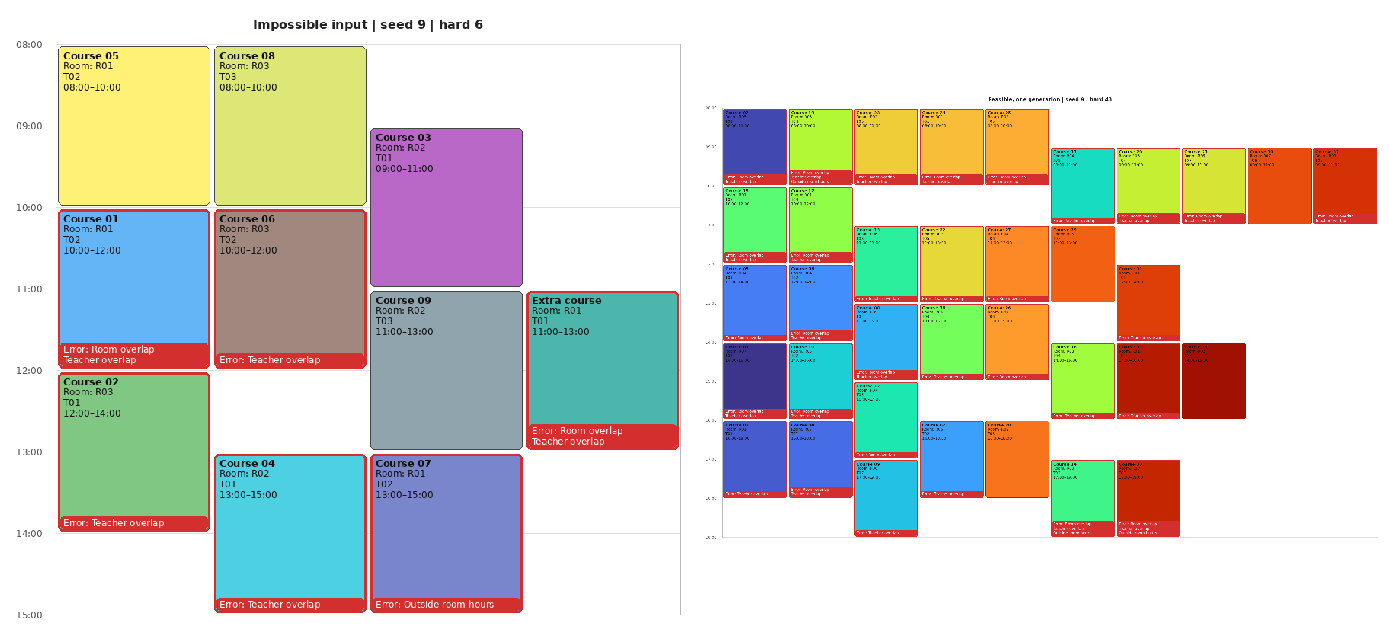

In [18]:
with use_case("room_overload"):
  demand = lec_dur.sum()
  capacity = (room_close - room_open).sum()
  print(f"Room overload | Demand: {demand}h | Capacity: {capacity}h")
  assert demand > capacity

with use_case("large_difficult"):
  assert penalty(witnesses["large_difficult"]) == 0
  print("Large difficult has a known valid timetable. This run has a deliberately short budget.")

failure_results = compare_runs("room_overload", {"Impossible input": {"generations": 20}})
failure_results.update(compare_runs("large_difficult", {"Feasible, one generation": {"generations": 1}}))
plot_comparison(failure_results)
show_comparison(failure_results)

### Results on the generated inputs

- The baseline found valid schedules for small easy in all three runs. On the
  other three feasible inputs it ran out of generations. Their median hard
  penalties were 1 (small difficult), 7 (large easy) and 28 (large difficult).
- On small difficult, 10% mutation gave the lowest median hard penalty (1)
  of the three rates tested. None of the rates found a valid schedule.
- On large difficult, the median hard penalties were 28 for the baseline,
  16 for initialization alone, 10 for custom operators alone and 11 for
  both. The custom operators helped here, and adding initialization did
  not improve their median result within this budget.
- Both soft-objective methods found valid schedules in all three small-easy
  runs. Their median preference and balance penalties were 2.0 h and 2.4 h
  each under the shared schedule selection rule.
- No seed solved either failure example. Room overload is impossible because
  it needs 20 room-hours and has 18. The one-generation case has a known
  feasible schedule, so its result indicates a search-budget failure.

These are results for the generated inputs and three fixed seeds. The cells
above also report elapsed times, which depend on the machine running them.


### LLM logs
Includes links to chat logs:

- All the links for the inital solution:
  - Task1 | Claude used for writing code based on ideas and simpler functions: 
      - https://claude.ai/share/6fb8eeb7-75c9-4016-bc15-8e21c2d924ff
      - For better display functions we only pasted code from a different LLM, but couldn't find the link
      - also used this as a prompt to generate a better prompt after discovering that we read the instructions wrong:
      <i>can you write me a prompt that you would be able to use to correctly modify the code so it works, along the lines it seems i have read wrong and we only need a one day schedule...</i>

  - Task 2 | Code generations based on ideas for functions:
    - https://share.gemini.google/wxpNhhAFnOF0
  - Task 2 | Debugging and recommendations:
    - https://chatgpt.com/share/6b06c54e-5d90-83ed-b55d-e0edbe335f18

  - Task 3 | Prefrence reading function:
    - https://share.gemini.google/sJgJwClbAc5E

  - Task 3 | Code implementation of ideas:
    - https://share.gemini.google/HTZfyEQ5oiX9

- Reworked solution:
  - https://chatgpt.com/share/6b072b70-3184-83ed-b52b-5ee7c4e00870 